## Configuration


In [262]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


participacions = pd.read_csv("../datos/clean/participacions.csv")
carreiras = pd.read_csv("../datos/clean/carreiras.csv")

carreiras = carreiras.sort_values("fecha").copy()

carreiras["orden"] = range(1, len(carreiras) + 1)
participacions = participacions.merge(
    carreiras[["id_carrera", "orden"]],
    on="id_carrera",
    how="left"
)

In [263]:
print(participacions.head())
print(carreiras.head())

      persoa_id  id_carrera   tipo_inscripcion  \
0  fe5bb85dce0a  carrera_01         por_prueba   
1  538a30f9a5e7  carrera_01  inscrito_circuito   
2  1feaf06d7d2e  carrera_01         por_prueba   
3  e0fa7a0d4838  carrera_01  inscrito_circuito   
4  5c832ee098e4  carrera_01         por_prueba   

                  resultado_cruce sexo categoria  puesto_general  \
0  sin coincidencia en el listado    M       SNR               1   
1       coinciden nombre y dorsal    M       SNR               2   
2  sin coincidencia en el listado    M     SUB23               3   
3       coinciden nombre y dorsal    M       SNR               4   
4  sin coincidencia en el listado    M       MS1               5   

   puesto_por_sexo  puesto_por_categoria  tiempo_segundos estado_tiempo  orden  
0              1.0                     1             1230        valido      1  
1              2.0                     2             1260        valido      1  
2              3.0                     1       

## Participación
1. Participantes por sexo en cada carreira e evolución ao longo do circuíto.


In [264]:

# unstack() hace un pivot , porque sino tendriamos dos indices que serian sexo e id_carrera 
# al hacerlo pasamos que el id_carrera sea columnas y el sexo el indice, y si no forzamos
participacion_agrupado = participacions.groupby(["id_carrera","sexo"])["persoa_id"].nunique().unstack()
print(participacion_agrupado)

sexo          F    M
id_carrera          
carrera_01  558  928
carrera_02  294  629
carrera_03  237  553
carrera_04  298  577
carrera_05  189  467
carrera_06  184  459


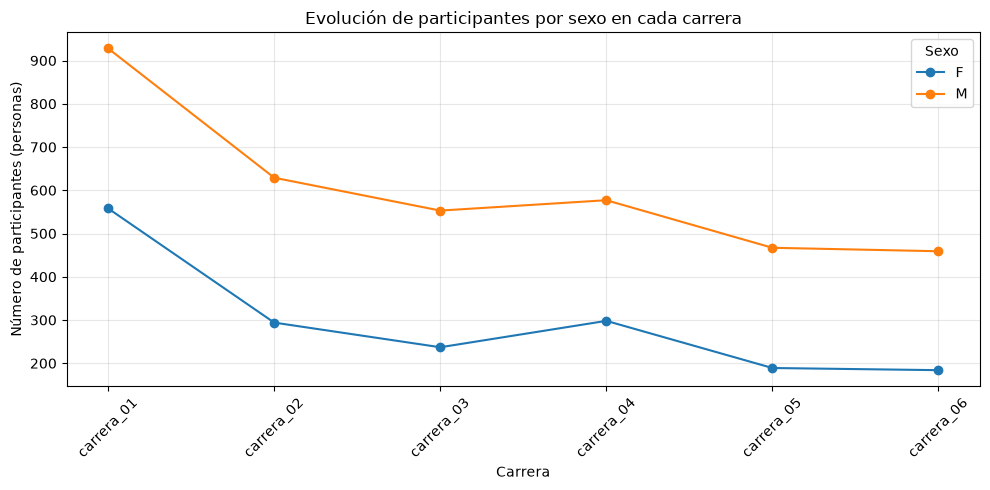

In [265]:
participacion_agrupado.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Evolución de participantes por sexo en cada carrera")
plt.xlabel("Carrera")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En esta gráfica observamos una disminucion progresiva de las personas masculinas a lo largo de la carerra, en cambio con respeto a la categoría femenina observamos tambien una disminucion con respecto a la primera y ultima carrera. En ambos casos vemos un ligero aumento justo en la carrera 4

2. Distribución por categorías de idade e diferenza entre sexos dentro de cada categoría.

In [266]:
participacions_idade = participacions.groupby(["categoria","sexo"])["persoa_id"].nunique().unstack()

print(participacions_idade)

sexo         F    M
categoria          
ESP          1    1
MS1        223  419
MS2        175  365
MS3         39  175
MS4         10   33
SNR        410  500
SUB20       21   18
SUB23       47   50


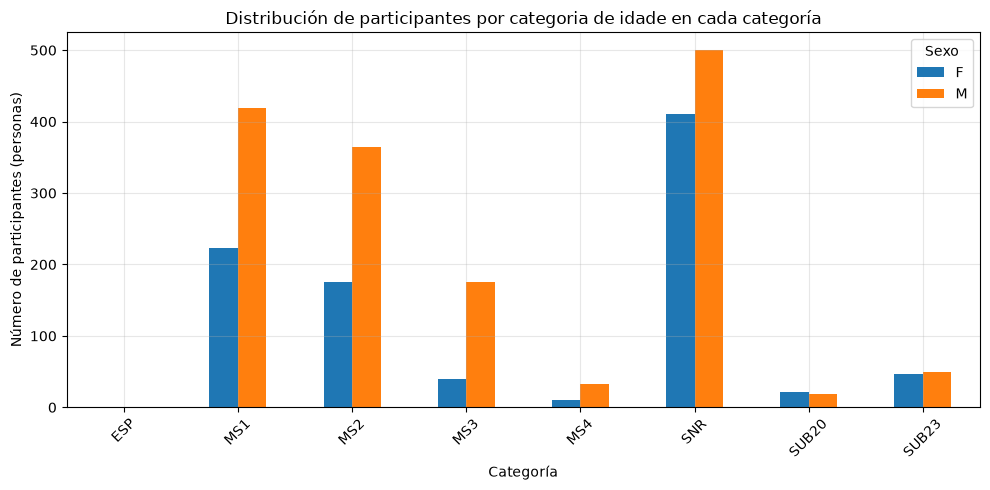

In [267]:
participacions_idade.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribución de participantes por categoria de idade en cada categoría")
plt.xlabel("Categoría")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Aqui observamos que la categoria con mas participantes en conjunto es "SNR". También en esta categoría es la que cuenta con mas femeninas y masculinos separados. En las categorías que empieza por MSX vemos que hay una grqn diferencia de cantidad de personas entre sexo

## Inscritos no circuíto e corredores por proba

1. En cada carreira, que porcentaxe de participantes están inscritos no circuíto e que porcentaxe corren por proba? Cambia ao longo do ano?

In [268]:
participacions_tipo = participacions.groupby(["id_carrera","tipo_inscripcion"])["persoa_id"].nunique().unstack().fillna(0)

participacions_tipo = participacions_tipo.drop(columns="no_resuelto")
# axis = 1 hace que opere horizontalmente
# Divide cada valor de una fila entre el total de esa carrera (axis = 0).
porcentajes = participacions_tipo.div(
    participacions_tipo.sum(axis=1), axis=0
) * 100

print(porcentajes.round(2))

tipo_inscripcion  inscrito_circuito  por_prueba
id_carrera                                     
carrera_01                    59.49       40.51
carrera_02                    78.33       21.67
carrera_03                    83.99       16.01
carrera_04                    72.60       27.40
carrera_05                    75.39       24.61
carrera_06                    76.26       23.74


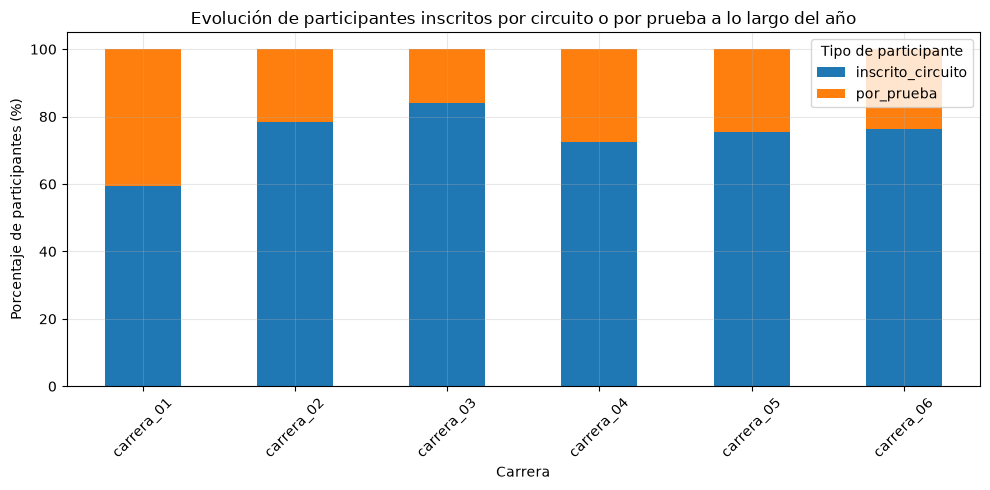

In [269]:
porcentajes.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Evolución de participantes inscritos por circuito o por prueba a lo largo del año")
plt.xlabel("Carrera")
plt.ylabel("Porcentaje de participantes (%)")
plt.legend(title="Tipo de participante")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2. En cantas carreiras participa de media unha persoa inscrita no circuíto? Cantas corren todas as carreiras, cantas abandonan e en que momento?

In [270]:
inscritos = participacions[
    participacions["tipo_inscripcion"] == "inscrito_circuito"
]

# Agrupamos por persona y miramos la columna id_carrera con las no repetidas, 
# entonces tenemos las carreras por personas
carrera_por_persona = inscritos.groupby(
    "persoa_id"
)["id_carrera"].nunique()

print("Cantidad de carreras de media que corren los inscritos en el circuito:",carrera_por_persona.mean())

# Total de carreras
total_carreras = carreiras["id_carrera"].nunique()

# Miramos si por carrera por personas es igual al numero total de carreras, para ver 
# cuantas personas completan todas las carreras.
completan = carrera_por_persona[
    carrera_por_persona == total_carreras
]

print("Personas que completan todas:", len(completan))

# Agrupamos los inscritos por persona, entonces tenemos una tabla por persona para ver el total de cada una en cada dato,
# Añadimos dos columnas nuevas una para ver la ultima carrera participada, y el numero de carreras participadas

ultima_participacion = inscritos.groupby(
    "persoa_id"
).agg(
    ultima_carrera=("orden", "max"),
    numero_carreras=("id_carrera", "nunique")
)

# Ultima carrera 
ultima_carrera_circuito = participacions["orden"].max()

# Abandono aparente , porque no podemos confirmar que por dejar de ir a una carrea hayan abandonado.
# Miramos si la ultima carrera de cada persona es menor a la ultima carrera de circuito.
abandonos_aparentes = ultima_participacion[
    ultima_participacion["ultima_carrera"] < ultima_carrera_circuito
]

# Agrupamos por la ultima carrera y contamos el numero de abandonos por su ultima carrea hecha
abandono_por_carrera = abandonos_aparentes.groupby(
    "ultima_carrera"
).size()

print("Personas que dejan de aparecer:", len(abandonos_aparentes))
print(abandono_por_carrera)


Cantidad de carreras de media que corren los inscritos en el circuito: 3.1782752902155886
Personas que completan todas: 150
Personas que dejan de aparecer: 721
ultima_carrera
1    149
2    112
3     99
4    181
5    180
dtype: int64


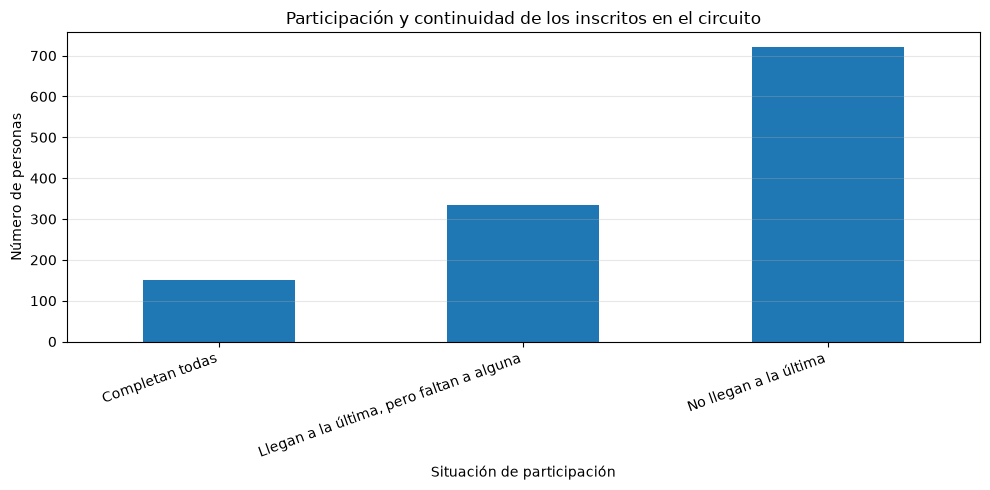

In [271]:
# Personas que completan todas las carreras
completan_todas = len(completan)

llegan_ultima = ultima_participacion[
    ultima_participacion["ultima_carrera"] == ultima_carrera_circuito
]

# Llegan a la última, pero no completan todas
llegan_pero_no_completan = (
    len(llegan_ultima) - completan_todas
)

# Dejan de aparecer antes de la última
no_llegan_ultima = len(abandonos_aparentes)

datos = pd.Series({
    "Completan todas": completan_todas,
    "Llegan a la última, pero faltan a alguna": llegan_pero_no_completan,
    "No llegan a la última": no_llegan_ultima
})

datos.plot(kind="bar", figsize=(10, 5))

plt.title("Participación y continuidad de los inscritos en el circuito")
plt.xlabel("Situación de participación")
plt.ylabel("Número de personas")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

3. Repiten as persoas que corren por proba? Hai quen corre varias carreiras sen inscribirse no circuíto?

In [272]:
inscritos_proba = participacions[participacions["tipo_inscripcion"] == "por_prueba"]

carreras_por_persona_prueba = inscritos_proba.groupby("persoa_id")["id_carrera"].nunique()

print("Cantidad de personas inscritas por prueba que repiten:",len(carreras_por_persona_prueba[carreras_por_persona_prueba > 1]))

Cantidad de personas inscritas por prueba que repiten: 182


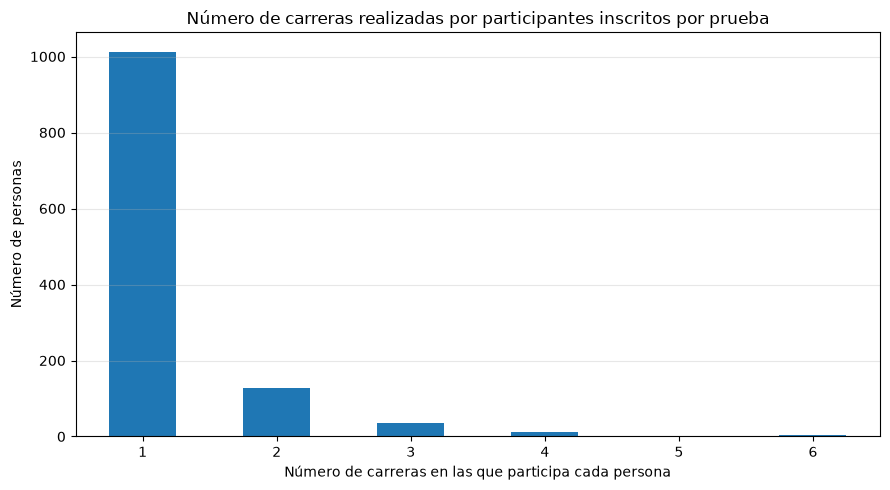

In [273]:
distribucion = carreras_por_persona_prueba.value_counts().sort_index()

distribucion.plot(kind="bar", figsize=(9, 5))

plt.title("Número de carreras realizadas por participantes inscritos por prueba")
plt.xlabel("Número de carreras en las que participa cada persona")
plt.ylabel("Número de personas")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Aqui vemos que si hay personas que repiten por prueba pero que la gran mayoría de inscritos por prueba corre una carrera. Aqui en esta gráfica vemos que tambien corren varias carreras sin inscribirse en el circuito.

4. Hai diferenzas por sexo e categoría entre inscritos no circuíto e corredores por proba?

In [274]:
circuito = inscritos.groupby(["sexo","categoria"])["persoa_id"].nunique().unstack()
por_proba = inscritos_proba.groupby(["sexo","categoria"])["persoa_id"].nunique().unstack()

print(circuito)
print()
print(por_proba)

categoria  ESP  MS1  MS2  MS3  MS4  SNR  SUB20  SUB23
sexo                                                 
F            1  105   88   25    7  120      3     14
M            1  229  226  111   25  224      9     19

categoria  MS1  MS2  MS3  MS4  SNR  SUB20  SUB23
sexo                                            
F          106   79   14    1  283     18     32
M          175  127   55    8  262      9     29


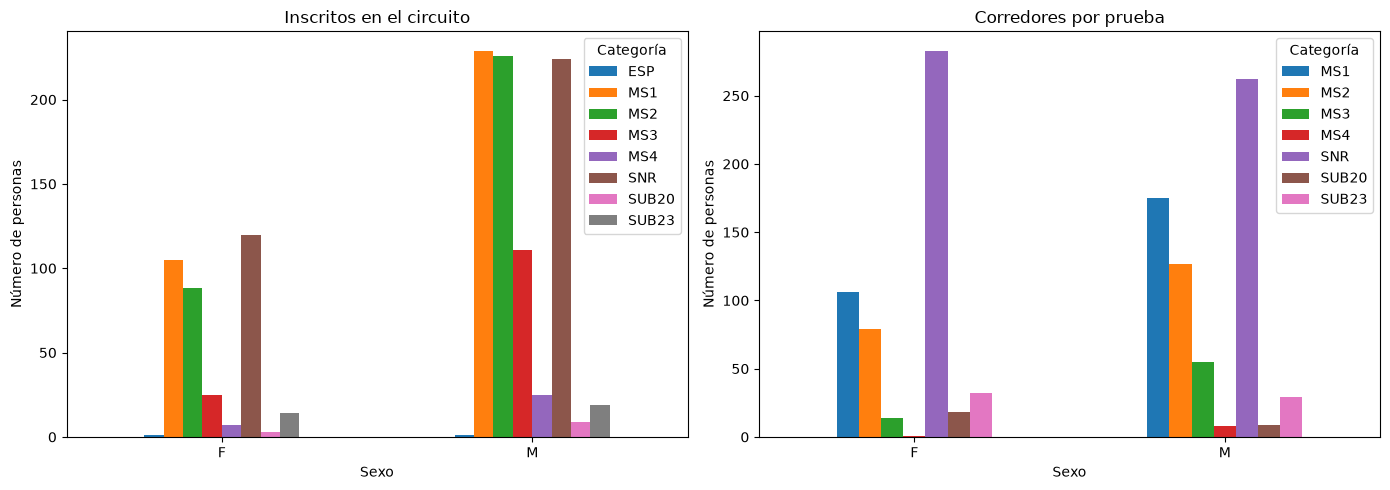

In [275]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

circuito.plot(kind="bar", ax=axes[0])
axes[0].set_title("Inscritos en el circuito")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Número de personas")
axes[0].legend(title="Categoría")
axes[0].tick_params(axis="x", rotation=0)

por_proba.plot(kind="bar", ax=axes[1])
axes[1].set_title("Corredores por prueba")
axes[1].set_xlabel("Sexo")
axes[1].set_ylabel("Número de personas")
axes[1].legend(title="Categoría")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Aqui vemos en la distribución por sexo y categoría entre los inscritos en el circuito y los corredores por prueba. Entre los inscritos en el circuito destacan las categorías MS1, MS2 y SNR, especialmente en hombres. En cambio, entre los corredores por prueba predomina claramente la categoría SNR siendo este la femenina mas predominante.

5. Os inscritos no circuíto quedan en mellores postos que os corredores por proba?

In [276]:
print(inscritos["puesto_general"].mean())
print(inscritos_proba["puesto_general"].mean())

444.950952256718
620.1810699588477


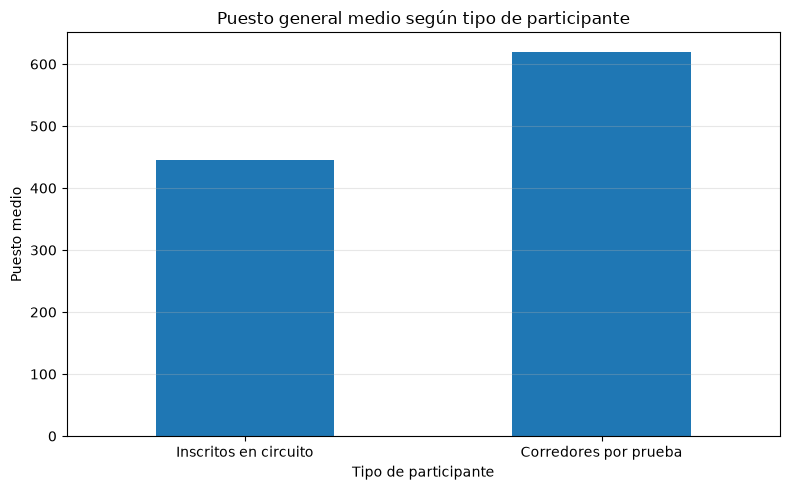

In [277]:
medias = pd.Series({
    "Inscritos en circuito": inscritos["puesto_general"].mean(),
    "Corredores por prueba": inscritos_proba["puesto_general"].mean()
})

medias.plot(kind="bar", figsize=(8, 5))

plt.title("Puesto general medio según tipo de participante")
plt.xlabel("Tipo de participante")
plt.ylabel("Puesto medio")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Por media general sí, los corredores inscritos en ciruito tienen mejores puestos que los corredores de prueba.

## Rendemento

1. Distribución dos tempos por categoría e sexo.

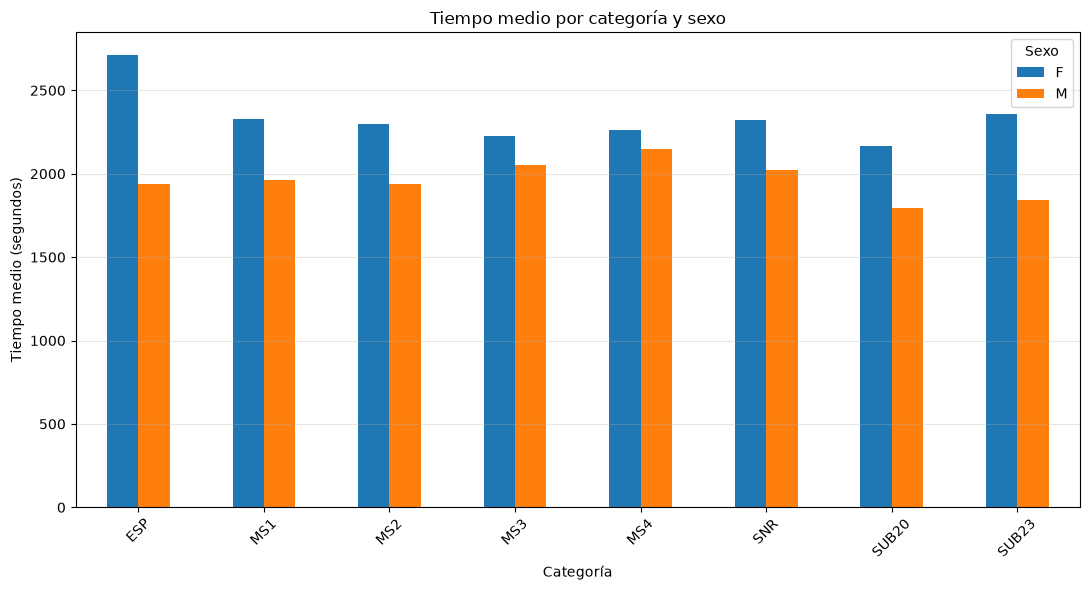

In [278]:
tiempos_medios = participacions.groupby(
    ["categoria", "sexo"]
)["tiempo_segundos"].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 6))

tiempos_medios.plot(kind="bar", ax=ax)

ax.set_title("Tiempo medio por categoría y sexo")
ax.set_xlabel("Categoría")
ax.set_ylabel("Tiempo medio (segundos)")
ax.legend(title="Sexo")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Aqui vemos que el tiempo medio es normalmente la misma diferencia entre masculinos y femeninos, pero cabe destacar que la categoria "ESP" hay una diferencia mayor, también es que hay una persona de cada en esta categoría nada más

2. Quen mellora máis entre a primeira e a última carreira en que participa? Melloran máis os inscritos no circuíto?

In [279]:
participacions_ordenadas = participacions.sort_values("orden")

# Cogemos la primera y ultima participacion de cada persona ya que lo ordenamos por orden
primera = participacions_ordenadas.groupby("persoa_id").first()
ultima = participacions_ordenadas.groupby("persoa_id").last()

mejoras = pd.DataFrame({
    "tipo_participante": primera["tipo_inscripcion"],
    "tiempo_primera": primera["tiempo_segundos"],
    "tiempo_ultima": ultima["tiempo_segundos"]
})

# Calculamos la mejora de cada persona
mejoras["mejora"] = (
    mejoras["tiempo_primera"] - mejoras["tiempo_ultima"]
)

# hacemos la media segun tipo de categoria
mejora_tipo = mejoras.groupby(
    "tipo_participante"
)["mejora"].mean()

print(mejora_tipo)

tipo_participante
inscrito_circuito    74.060531
no_resuelto           0.000000
por_prueba           19.831799
Name: mejora, dtype: float64


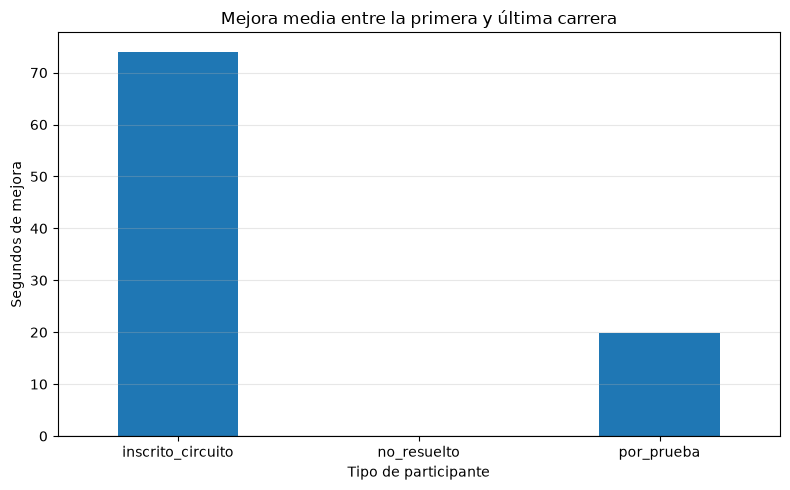

In [280]:
mejora_tipo.plot(kind="bar", figsize=(8, 5))

plt.title("Mejora media entre la primera y última carrera")
plt.xlabel("Tipo de participante")
plt.ylabel("Segundos de mejora")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Aqui vemos que que los inscritos en circuito mejoran mas sus tiempos en comparación con los inscritos en prueba